To build this model to detect Crop Disease, we employed Computer Vision using Transfer learning and Fine-tuning

We employed the method outlined in https://www.tensorflow.org/tutorials/images/transfer_learning, plus the method displayed in class

Importing Necessary Libraries

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

Download Dataset from Mendeley

In [2]:
!wget -O "dataset.zip" "https://data.mendeley.com/public-files/datasets/tywbtsjrjv/files/b4e3a32f-c0bd-4060-81e9-6144231f2520/file_downloaded"

--2026-10-14 19:12:25--  https://data.mendeley.com/public-files/datasets/tywbtsjrjv/files/b4e3a32f-c0bd-4060-81e9-6144231f2520/file_downloaded
Resolving data.mendeley.com (data.mendeley.com)... 162.159.130.86, 162.159.133.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.130.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/349ac012-2948-4172-bbba-3bf8f76596fd [following]
--2026-10-14 19:12:26--  https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/349ac012-2948-4172-bbba-3bf8f76596fd
Resolving prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)... 52.92.2.138, 52.92.3.234, 52.92.20.130, ...
Connecting to prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)|52.92.2.138|:443...

Unzip Dataset

In [3]:
!unzip /content/dataset.zip

Streaming output truncated to the last 5000 lines.
  inflating: Plant_leave_diseases_dataset_with_augmentation/Tomato___Tomato_Yellow_Leaf_Curl_Virus/image (132).JPG  
  inflating: Plant_leave_diseases_dataset_with_augmentation/Tomato___Tomato_Yellow_Leaf_Curl_Virus/image (1320).JPG  
  inflating: Plant_leave_diseases_dataset_with_augmentation/Tomato___Tomato_Yellow_Leaf_Curl_Virus/image (1321).JPG  
  inflating: Plant_leave_diseases_dataset_with_augmentation/Tomato___Tomato_Yellow_Leaf_Curl_Virus/image (1322).JPG  
  inflating: Plant_leave_diseases_dataset_with_augmentation/Tomato___Tomato_Yellow_Leaf_Curl_Virus/image (1323).JPG  
  inflating: Plant_leave_diseases_dataset_with_augmentation/Tomato___Tomato_Yellow_Leaf_Curl_Virus/image (1324).JPG  
  inflating: Plant_leave_diseases_dataset_with_augmentation/Tomato___Tomato_Yellow_Leaf_Curl_Virus/image (1325).JPG  
  inflating: Plant_leave_diseases_dataset_with_augmentation/Tomato___Tomato_Yellow_Leaf_Curl_Virus/image (1326).JPG  
  infl

Split Dataset into Train, Validation and Test

In [4]:
!pip install split-folders

In [5]:
import splitfolders
splitfolders.ratio('/content/Plant_leave_diseases_dataset_with_augmentation', output="dataset", seed=1337, ratio=(.8, .1,.1))

Copying files: 61486 files [00:25, 2396.70 files/s]


Data Preprocesssing

In [6]:
train_dir = "/content/dataset/train"
validation_dir = "/content/dataset/val"
test_dir = "/content/dataset/test"

BATCH_SIZE = 32
IMG_SIZE = (160, 160)

train_dataset = tf.keras.utils.image_dataset_from_directory(train_dir, shuffle=True, batch_size=BATCH_SIZE, image_size=IMG_SIZE)
validation_dataset = tf.keras.utils.image_dataset_from_directory(validation_dir, shuffle=True, batch_size=BATCH_SIZE, image_size=IMG_SIZE)
test_dataset = tf.keras.utils.image_dataset_from_directory(test_dir,batch_size=BATCH_SIZE,image_size=IMG_SIZE)

Found 49179 files belonging to 39 classes.
Found 6139 files belonging to 39 classes.
Found 6168 files belonging to 39 classes.


Visualize Data from Training Set

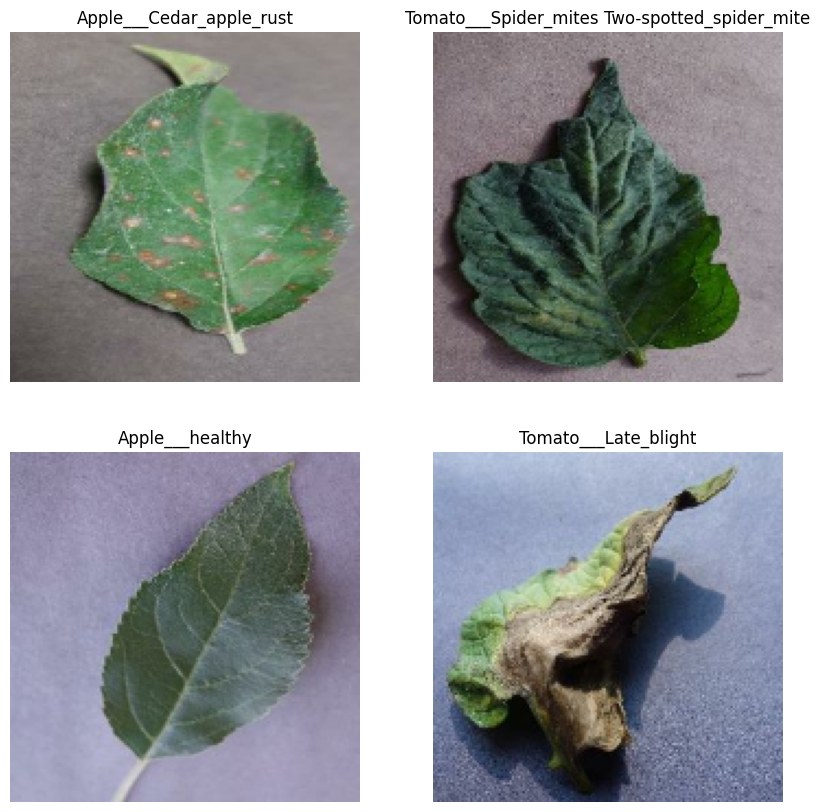

In [7]:
class_names = train_dataset.class_names

plt.figure(figsize=(10, 10))
for images, labels in train_dataset.take(1):
  for i in range(4):
    ax = plt.subplot(2, 2, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

Configure the Datasets for Performance

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

Since Data is already Augmented from Source(Mendeley), we skip this step as Overfitting won't occur

Rescale Pixel Values so the model would understand

In [9]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

Create the base model from the pre-trained convnets

In [10]:
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights='imagenet',
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [11]:
image_batch, label_batch = next(iter(train_dataset))
feature_batch = base_model(image_batch)
print(feature_batch.shape)

(32, 5, 5, 1280)


Feature Extraction

In [12]:
# Freeze the convolutional base
base_model.trainable = False

In [13]:
# View the base model architecture
base_model.summary()

Model: "mobilenetv2_1.00_160"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 80, 80,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 80, 80,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 80, 80,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 80, 80,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 80, 80,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 80, 80,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 80, 80,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 80, 80,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 81, 81,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 40, 40,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 40, 40,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 40, 40,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 40, 40,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

Add a classification head to generate predictions from the block of features

In [14]:
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(32, 1280)


Apply the Dense layer to convert the features into a single prediction per image

In [15]:
prediction_layer = tf.keras.layers.Dense(len(class_names), activation='sigmoid')
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(32, 39)


Build a model by chaining together rescaling, base_model and feature extractor layers using the Keras Functional API

In [16]:
inputs = tf.keras.Input(shape=(160, 160, 3))
x = preprocess_input(inputs)
x = base_model(x, training=False)
x = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

In [17]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 39)             │        49,959 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,307,943 (8.80 MB)

 Trainable params: 49,959 (195.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

There are 49,959 trainable parameters divided into 2 variables as seen below

In [18]:
len(model.trainable_variables)

2

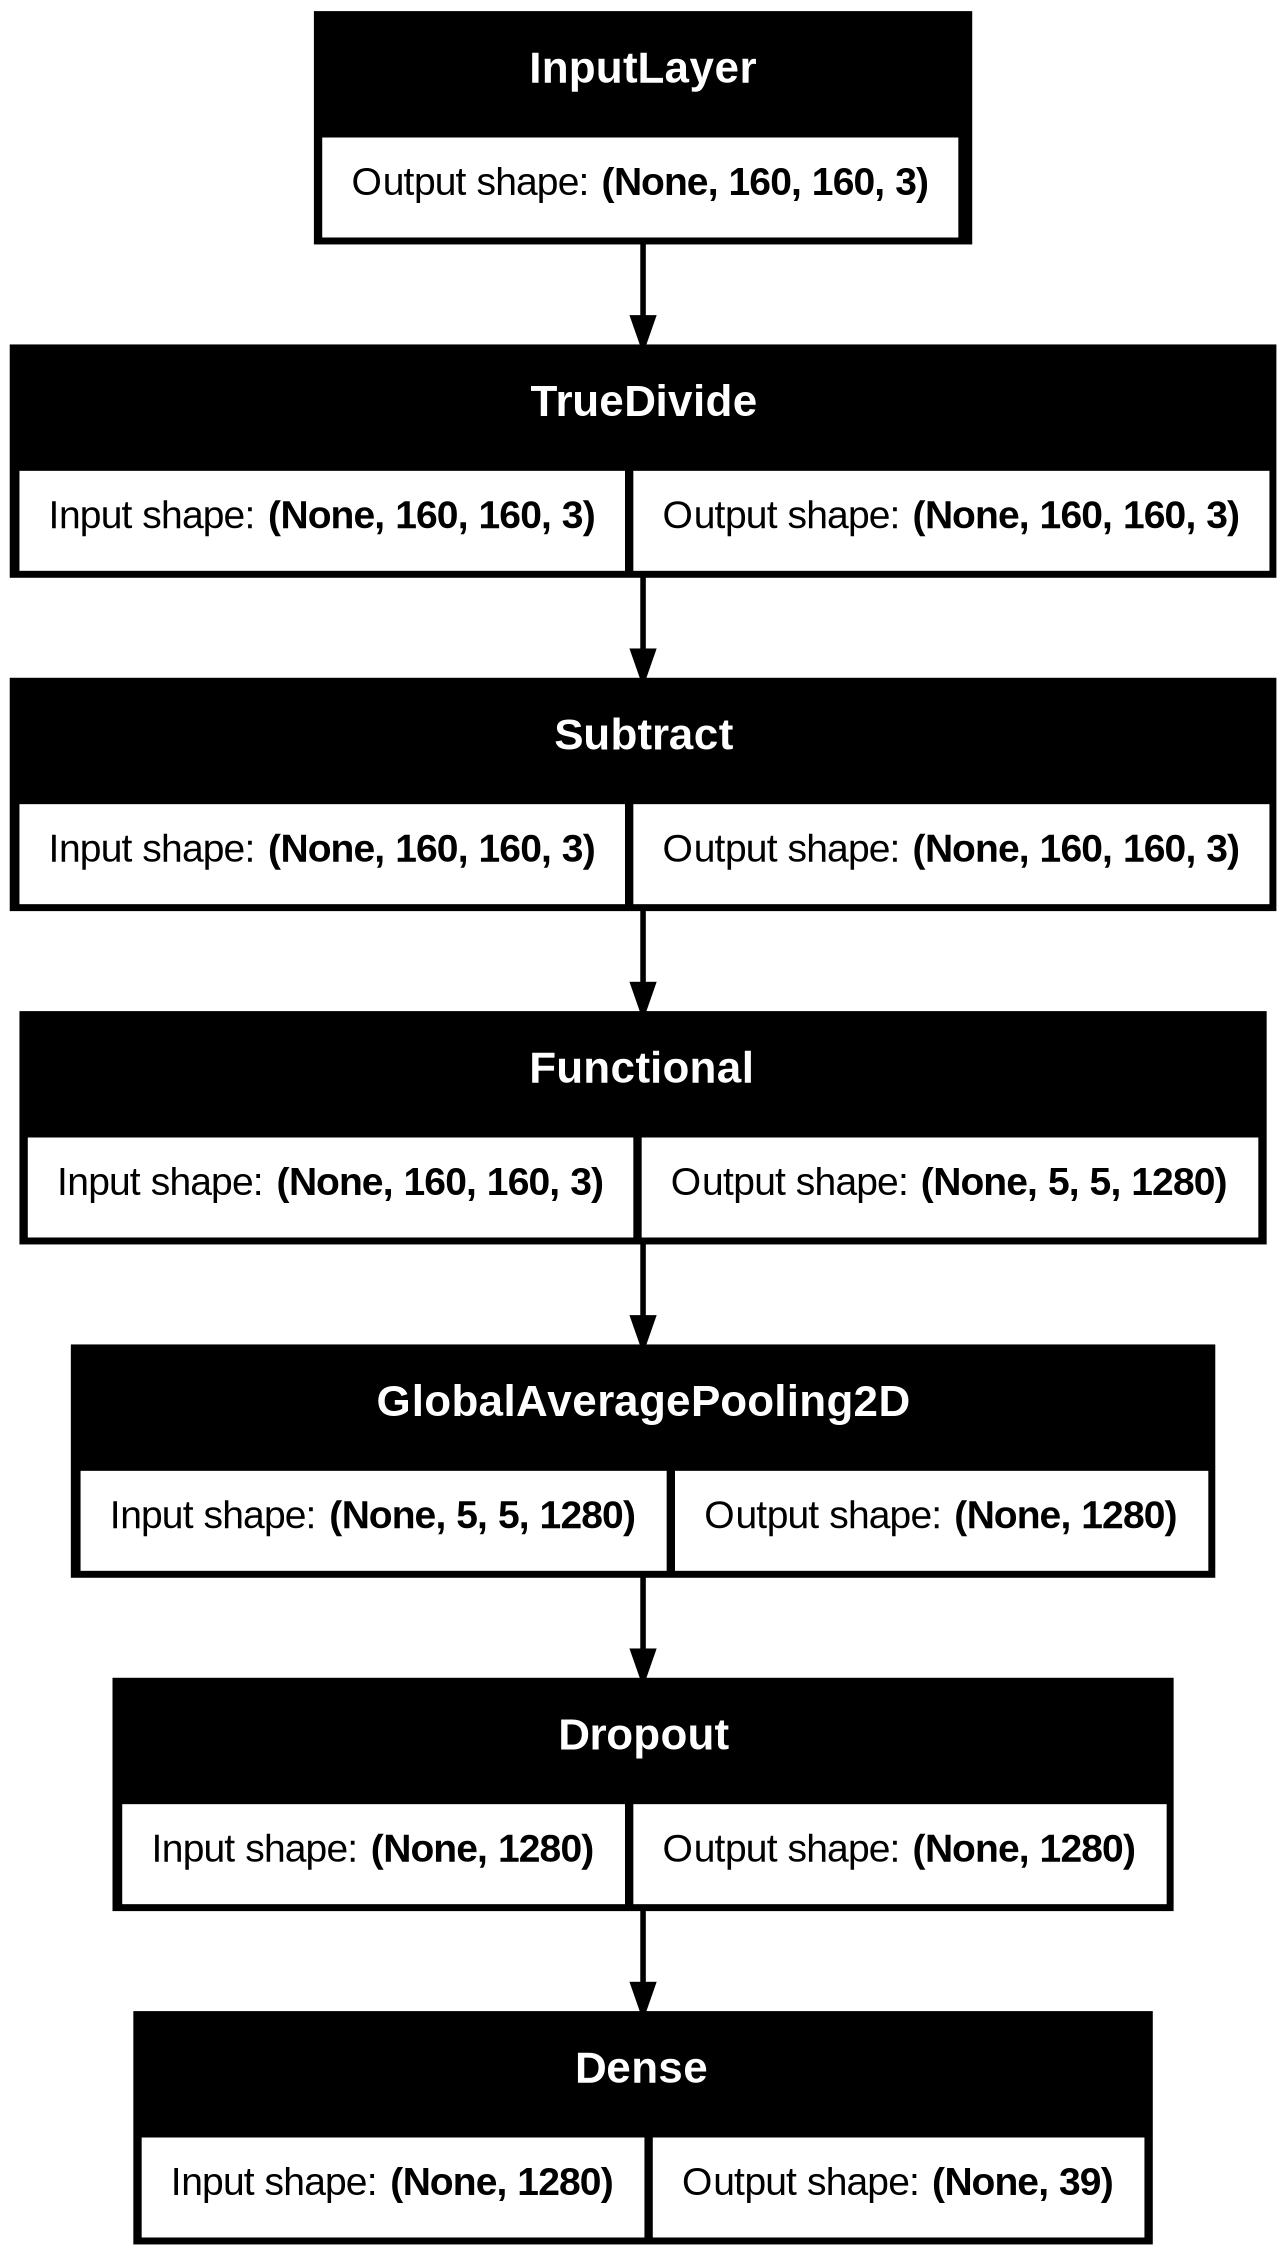

In [19]:
tf.keras.utils.plot_model(model, show_shapes=True)

Compile the Model using SparseCategoricalAccuracy

In [20]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy", metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')])

In [21]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

Train the Model

In [22]:
# Check the baseline performance before training
loss0, accuracy0 = model.evaluate(validation_dataset)

192/192 ━━━━━━━━━━━━━━━━━━━━ 19s 47ms/step - accuracy: 0.0205 - loss: 4.4997


In [23]:
print("initial loss: {:.2f}".format(loss0))
print("initial accuracy: {:.2f}".format(accuracy0))

initial loss: 4.50
initial accuracy: 0.02


In [24]:
initial_epochs = 10

In [25]:
history_phase1 = model.fit(
    train_dataset,
    epochs= initial_epochs,
    validation_data=validation_dataset,
    callbacks=[early_stopping]
)

Epoch 1/10
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 57s 31ms/step - accuracy: 0.8822 - loss: 0.4159 - val_accuracy: 0.9471 - val_loss: 0.1701
Epoch 2/10
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 74s 29ms/step - accuracy: 0.9479 - loss: 0.1639 - val_accuracy: 0.9578 - val_loss: 0.1335
Epoch 3/10
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 82s 29ms/step - accuracy: 0.9592 - loss: 0.1263 - val_accuracy: 0.9575 - val_loss: 0.1263
Epoch 4/10
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 44s 29ms/step - accuracy: 0.9623 - loss: 0.1116 - val_accuracy: 0.9612 - val_loss: 0.1234
Epoch 5/10
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 44s 29ms/step - accuracy: 0.9651 - loss: 0.1032 - val_accuracy: 0.9664 - val_loss: 0.1151
Epoch 6/10
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 82s 29ms/step - accuracy: 0.9687 - loss: 0.0911 - val_accuracy: 0.9635 - val_loss: 0.1167
Epoch 7/10
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 44s 29ms/step - accuracy: 0.9701 - loss: 0.0855 - val_accuracy: 0.9658 - val_loss: 0.1162
Epoch 8/10
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 82s 28ms/step - accuracy: 0.9712 -

In [26]:
loss, accuracy = model.evaluate(test_dataset)

print(f"Loss: {loss:.4f}")
print(f"Accuracy: {accuracy:.4f}")

193/193 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - accuracy: 0.9690 - loss: 0.1018
Loss: 0.1018
Accuracy: 0.9690


View learning curves of the training and validation accuracy/loss when using the base model as a fixed feature extractor

In [27]:
acc = history_phase1.history['accuracy']
val_acc = history_phase1.history['val_accuracy']

loss = history_phase1.history['loss']
val_loss = history_phase1.history['val_loss']

View Accuracy and Loss Plot

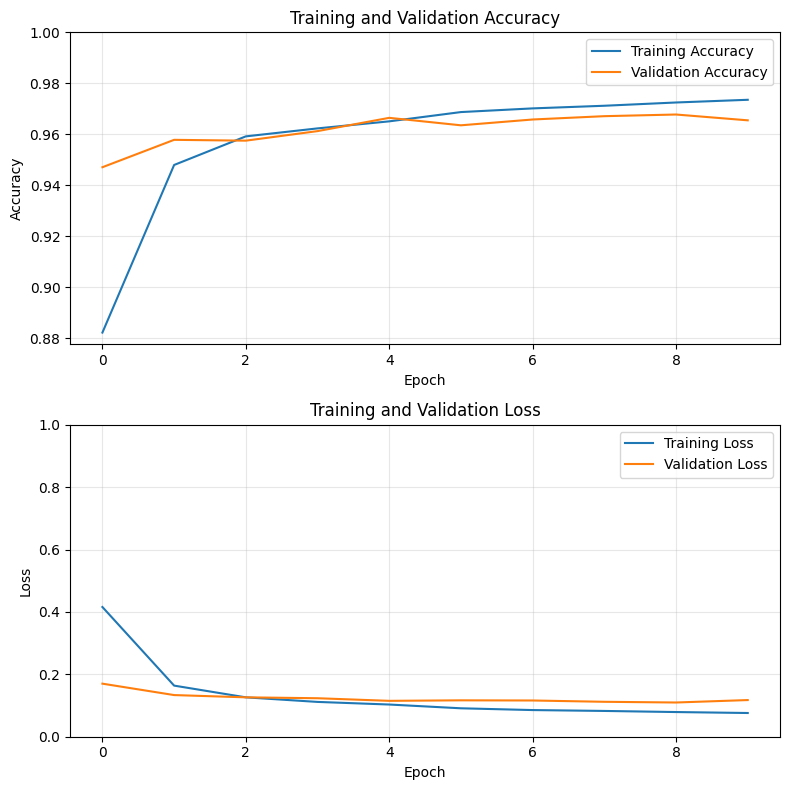

In [28]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(8, 8))

# Accuracy Plot
axes[0].plot(acc, label="Training Accuracy")
axes[0].plot(val_acc, label="Validation Accuracy")
axes[0].legend()
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim([min(axes[0].get_ylim()), 1])
axes[0].set_title("Training and Validation Accuracy")
axes[0].grid(alpha=.3)

# Loss Plot
axes[1].plot(loss, label="Training Loss")
axes[1].plot(val_loss, label="Validation Loss")
axes[1].legend()
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_ylim([0, 1.0])
axes[1].set_title("Training and Validation Loss")
axes[1].grid(alpha=.3)

plt.tight_layout()

plt.show()

Fine tuning to increase the performance of the model

In [29]:
base_model.trainable = True

In [30]:
# Let's take a look to see how many layers are in the base model
print("Number of layers in the base model: ", len(base_model.layers))

Number of layers in the base model:  154


In [31]:
# Fine-tune from this layer onwards
fine_tune_at = 100

# Freeze all the layers before the `fine_tune_at` layer
for layer in base_model.layers[:fine_tune_at]:
  layer.trainable = False

In [32]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy", metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')])

In [33]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [34]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 39)             │        49,959 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,307,943 (8.80 MB)

 Trainable params: 1,911,399 (7.29 MB)

 Non-trainable params: 396,544 (1.51 MB)

There are 1,911,399 trainable parameters divided into 333 variables as seen below

In [35]:
len(model.trainable_variables)

56

In [36]:
final_epochs = 10
total_epochs = initial_epochs + final_epochs

Model Training with Fine-tuned Dataset

In [37]:
history_phase2 = model.fit(
    train_dataset,
    epochs= total_epochs,
    validation_data=validation_dataset,
    callbacks=[early_stopping]
)

Epoch 1/20
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 114s 56ms/step - accuracy: 0.9220 - loss: 0.2833 - val_accuracy: 0.7350 - val_loss: 2.6165
Epoch 2/20
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 99s 39ms/step - accuracy: 0.9621 - loss: 0.1243 - val_accuracy: 0.6879 - val_loss: 3.4354
Epoch 3/20
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 61s 40ms/step - accuracy: 0.9716 - loss: 0.0923 - val_accuracy: 0.7267 - val_loss: 2.9868
Epoch 4/20
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 83s 40ms/step - accuracy: 0.9760 - loss: 0.0818 - val_accuracy: 0.9234 - val_loss: 0.5171
Epoch 5/20
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 76s 36ms/step - accuracy: 0.9800 - loss: 0.0658 - val_accuracy: 0.8607 - val_loss: 1.0824
Epoch 6/20
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 56s 36ms/step - accuracy: 0.9831 - loss: 0.0571 - val_accuracy: 0.9078 - val_loss: 0.6491
Epoch 7/20
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 50s 33ms/step - accuracy: 0.9850 - loss: 0.0483 - val_accuracy: 0.9335 - val_loss: 0.3911
Epoch 8/20
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 50s 32ms/step - accuracy: 0.9875 

In [38]:
# Combine histories from Phase 1 and Phase 2
acc += history_phase2.history['accuracy']
val_acc += history_phase2.history['val_accuracy']

loss += history_phase2.history['loss']
val_loss += history_phase2.history['val_loss']

View Accuracy and Loss plot

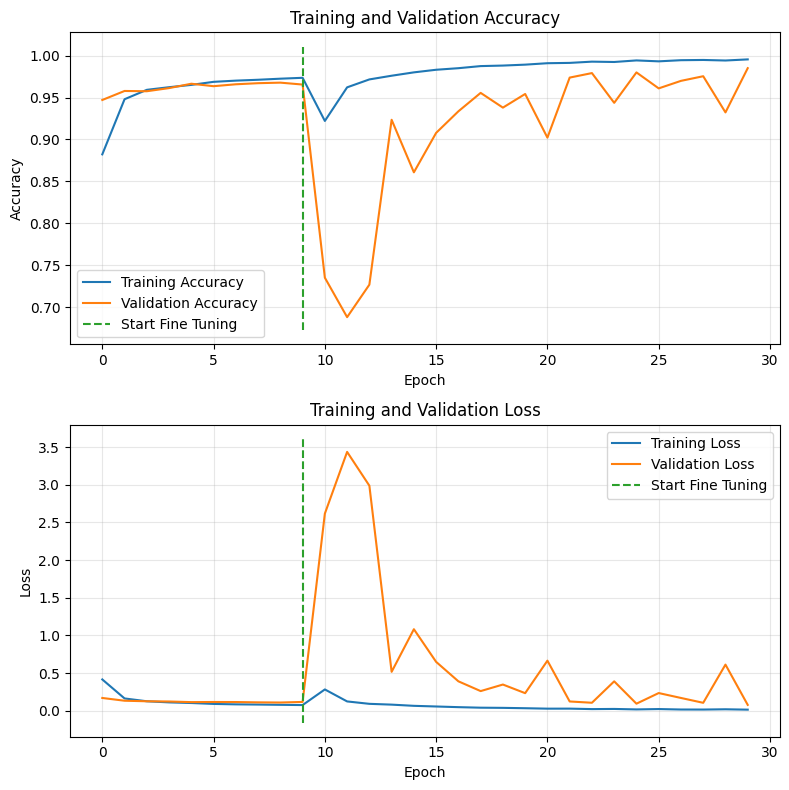

In [39]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(8, 8))

# Accuracy Plot
axes[0].plot(acc, label="Training Accuracy")
axes[0].plot(val_acc, label="Validation Accuracy")
axes[0].plot(
    [initial_epochs - 1, initial_epochs - 1],
    axes[0].get_ylim(),
    linestyle="--",
    label="Start Fine Tuning"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Training and Validation Accuracy")
axes[0].legend()
axes[0].grid(alpha=.3)

# Loss Plot
axes[1].plot(loss, label="Training Loss")
axes[1].plot(val_loss, label="Validation Loss")
axes[1].plot(
    [initial_epochs - 1, initial_epochs - 1],
    axes[1].get_ylim(),
    linestyle="--",
    label="Start Fine Tuning"
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_title("Training and Validation Loss")
axes[1].legend()
axes[1].grid(alpha=.3)

plt.tight_layout()

plt.show()

In [40]:
loss, accuracy = model.evaluate(test_dataset)
print('Test accuracy :', accuracy)

193/193 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.9843 - loss: 0.0699
Test accuracy : 0.9842736721038818


Cross-check Predictions and labels for accuracy

Predictions:
 [23 25 36  2 16 17 36 17 16 22 34 35 24  8 20 16 38  0  7 17 24 36  9 20
 35 15 25 16 16  7 15  1]
Labels:
 [23 25 36  2 16 17 36 17 16 22 34 35 24  8 20 16 38  0  7 17 24 36  9 20
 34 15 25 16 16  7 15  1]


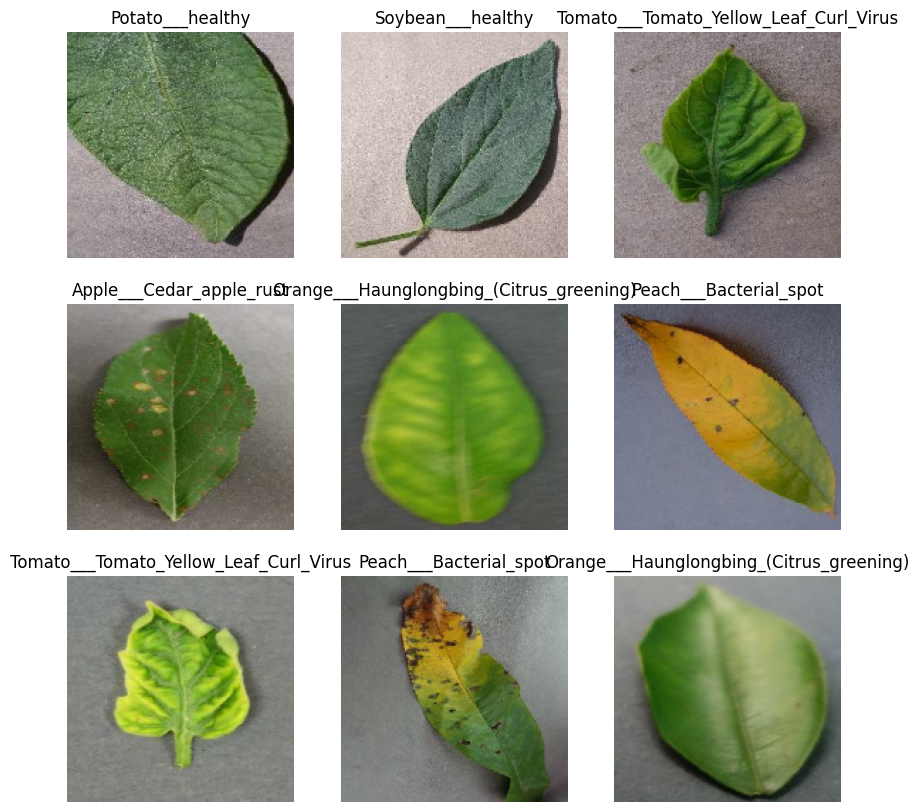

In [41]:
# Retrieve a batch of images from the test set
image_batch, label_batch = test_dataset.as_numpy_iterator().next()
predictions = model.predict_on_batch(image_batch)
predictions = tf.argmax(predictions,axis=1)

print('Predictions:\n', predictions.numpy())
print('Labels:\n', label_batch)

plt.figure(figsize=(10, 10))
for i in range(9):
  ax = plt.subplot(3, 3, i + 1)
  plt.imshow(image_batch[i].astype("uint8"))
  plt.title(class_names[predictions[i]])
  plt.axis("off")

Iterate over the entire test dataset to collect all true labels and predictions, then use scikit-learn and seaborn to compute and plot a confusion matrix.

In [42]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

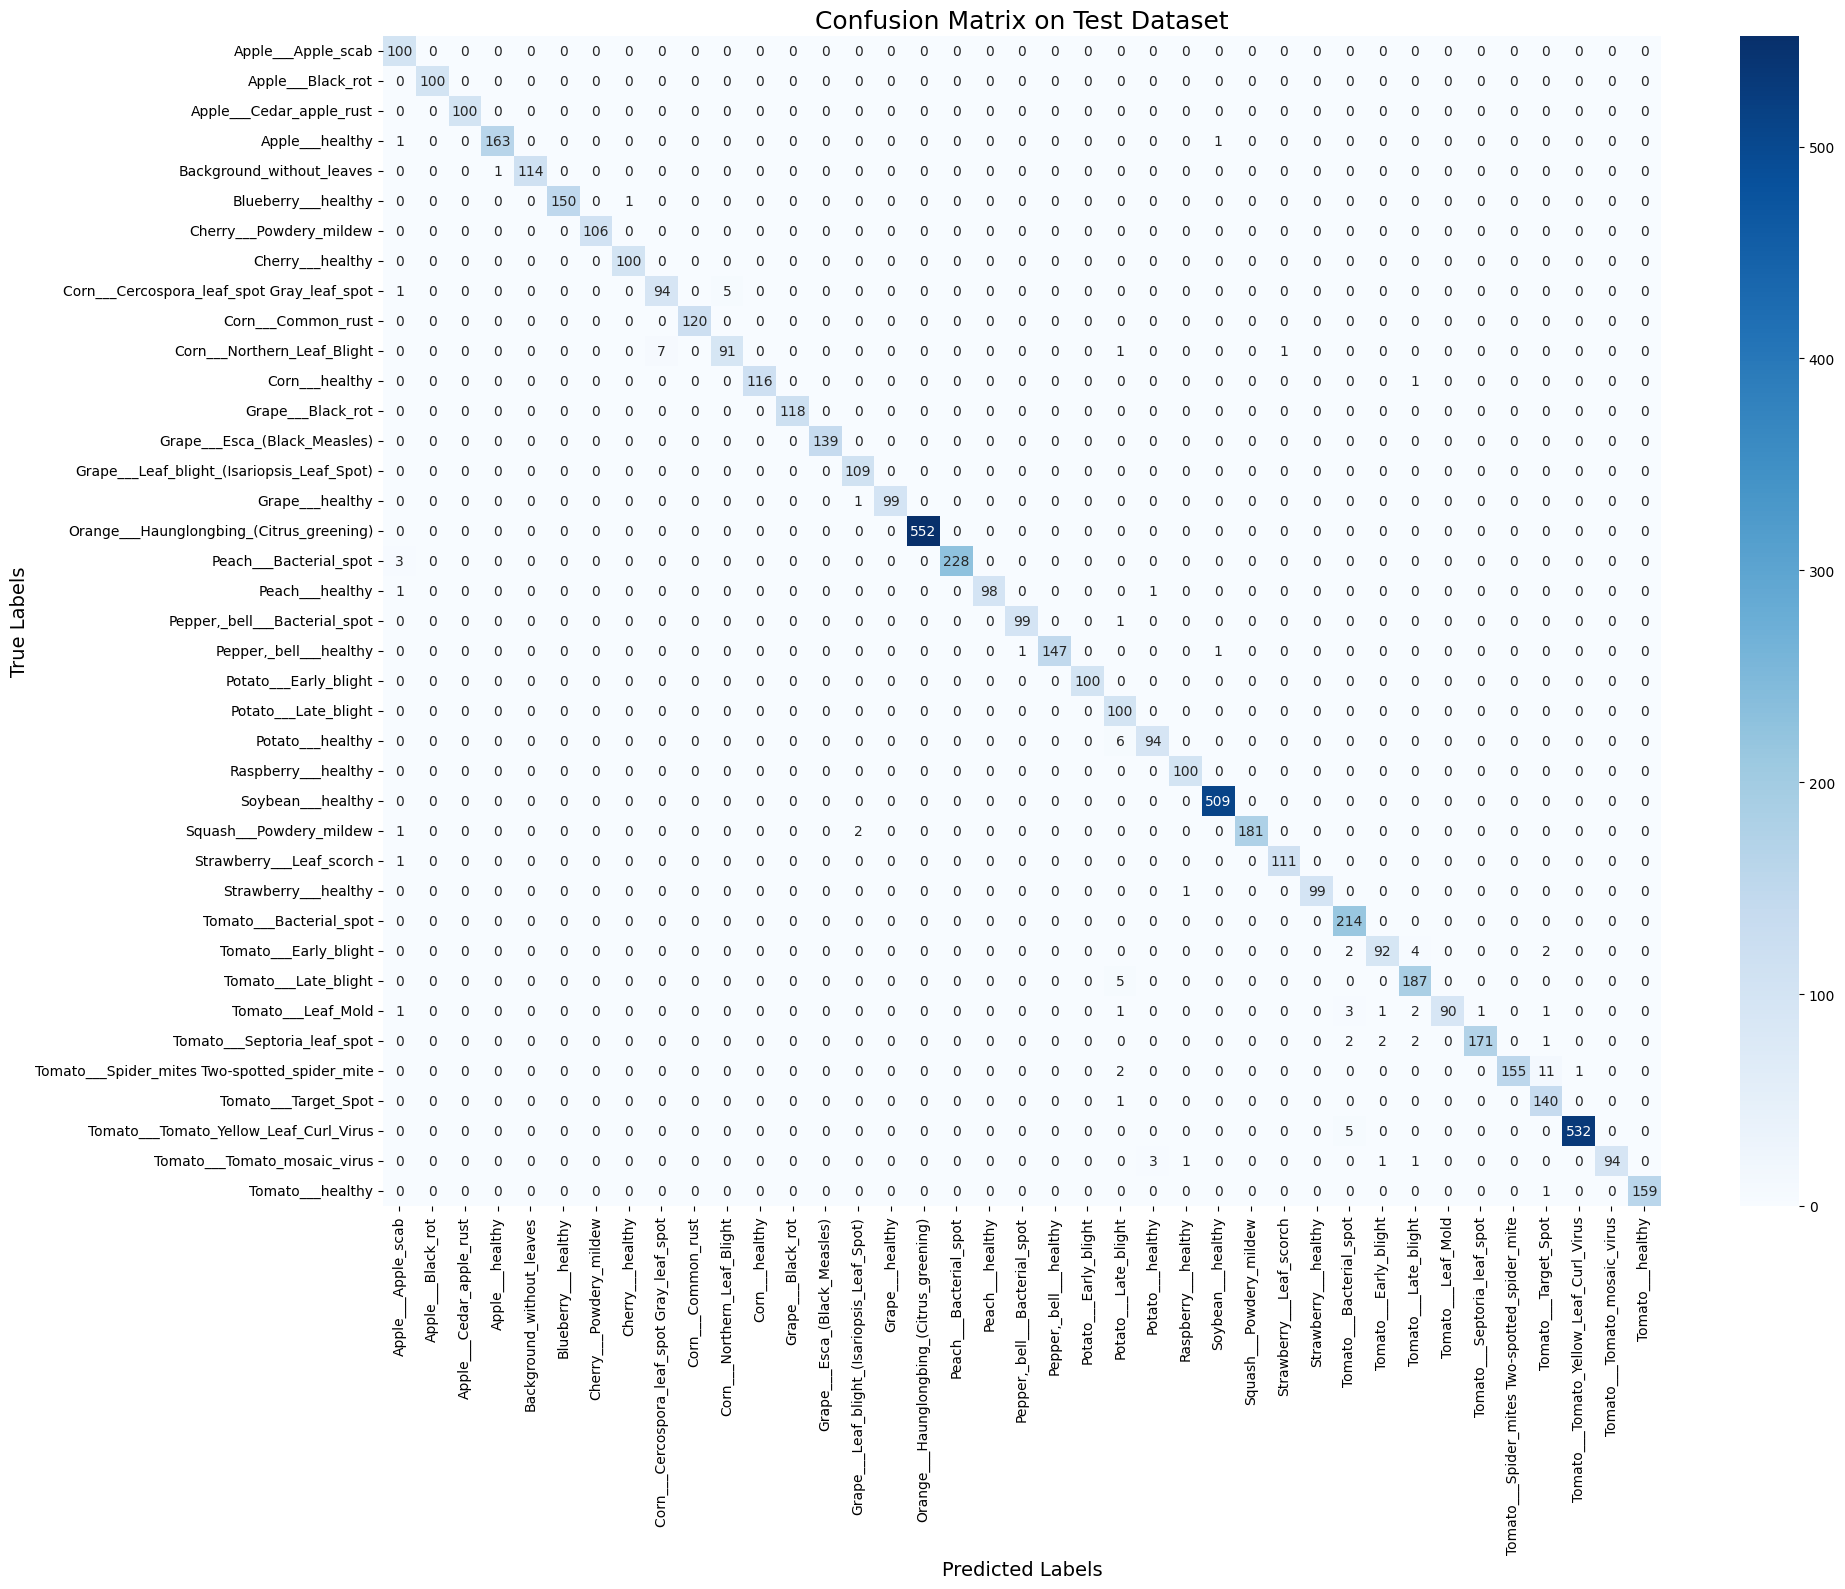

In [43]:
# 1. Collect all true labels and predictions from the test dataset
y_true = []
y_pred = []

for images, labels in test_dataset:
    preds = model.predict(images, verbose=0)
    pred_classes = np.argmax(preds, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(pred_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 2. Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# 3. Plot confusion matrix
plt.figure(figsize=(20, 16))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix on Test Dataset', fontsize=18)
plt.xlabel('Predicted Labels', fontsize=14)
plt.ylabel('True Labels', fontsize=14)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

To better understand model weaknesses, we will extract the off-diagonal elements of our confusion matrix and list the pairs of classes that are most frequently confused with one another.

In [44]:
# Get off-diagonal elements (where True label != Predicted label)
misclassified_indices = np.where(cm > 0)

misclassified_pairs = []
for true_idx, pred_idx in zip(*misclassified_indices):
    if true_idx != pred_idx:
        count = cm[true_idx, pred_idx]
        misclassified_pairs.append({
            'True Class': class_names[true_idx],
            'Predicted Class': class_names[pred_idx],
            'Count': count
        })

# Convert to DataFrame and sort by count in descending order
misclassified_df = pd.DataFrame(misclassified_pairs)
if not misclassified_df.empty:
    misclassified_df = misclassified_df.sort_values(by='Count', ascending=False).reset_index(drop=True)
    print("Top 10 Most Frequently Misclassified Pairs:")
    display(misclassified_df.head(10))
else:
    print("No misclassifications found! The model achieved perfect classification on the test set.")

Top 10 Most Frequently Misclassified Pairs:


,True Class,Predicted Class,Count
0,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,11
1,Corn___Northern_Leaf_Blight,Corn___Cercospora_leaf_spot Gray_leaf_spot,7
2,Potato___healthy,Potato___Late_blight,6
3,Tomato___Late_blight,Potato___Late_blight,5
4,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Bacterial_spot,5
5,Corn___Cercospora_leaf_spot Gray_leaf_spot,Corn___Northern_Leaf_Blight,5
6,Tomato___Early_blight,Tomato___Late_blight,4
7,Tomato___Tomato_mosaic_virus,Potato___healthy,3
8,Tomato___Leaf_Mold,Tomato___Bacterial_spot,3
9,Peach___Bacterial_spot,Apple___Apple_scab,3




To thoroughly evaluate the model's performance, we will calculate the Precision, Recall, and F1-Score for each class, along with the macro and weighted averages.

In [45]:
from sklearn.metrics import classification_report

# Generate classification report
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)

# Convert to DataFrame for a cleaner presentation
report_df = pd.DataFrame(report).transpose()

print("Overall Classification Metrics (Summary):")
display(report_df.tail(3))

print("\nDetailed Metrics per Class:")
display(report_df.iloc[:-3])

Overall Classification Metrics (Summary):


,precision,recall,f1-score,support
accuracy,0.984274,0.984274,0.984274,0.984274
macro avg,0.981254,0.980552,0.980441,6168.000000
weighted avg,0.985140,0.984274,0.984356,6168.000000



Detailed Metrics per Class:


,precision,recall,f1-score,support
Apple___Apple_scab,0.917431,1.000000,0.956938,100.0
Apple___Black_rot,1.000000,1.000000,1.000000,100.0
Apple___Cedar_apple_rust,1.000000,1.000000,1.000000,100.0
Apple___healthy,0.993902,0.987879,0.990881,165.0
Background_without_leaves,1.000000,0.991304,0.995633,115.0
Blueberry___healthy,1.000000,0.993377,0.996678,151.0
Cherry___Powdery_mildew,1.000000,1.000000,1.000000,106.0
Cherry___healthy,0.990099,1.000000,0.995025,100.0
Corn___Cercospora_leaf_spot Gray_leaf_spot,0.930693,0.940000,0.935323,100.0
Corn___Common_rust,1.000000,1.000000,1.000000,120.0


In [46]:
model.save("crop_disease_detector_model.keras")

### **Save Model to Google Drive**

We will mount Google Drive and copy the trained Keras model (`crop_disease_detector_model.keras`) into your drive directory for permanent storage.

In [47]:
from google.colab import drive
import shutil

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define source and destination paths
source_path = 'crop_disease_detector_model.keras'
destination_dir = '/content/drive/MyDrive/'
destination_path = f"{destination_dir}crop_disease_detector_model.keras"

# 3. Copy the file
try:
    shutil.copy(source_path, destination_path)
    print(f"Successfully saved the model to Google Drive at: {destination_path}")
except Exception as e:
    print(f"An error occurred while saving to Google Drive: {e}")

Mounted at /content/drive
Successfully saved the model to Google Drive at: /content/drive/MyDrive/crop_disease_detector_model.keras
